# CALPHAD Co–Ni Binary Phase Diagrams



This notebook generates the three requested Co–Ni views using `CoNi-24Per.tdb`. “Atomic mass” is interpreted here as **atomic percent (at.%)**, so composition is calculated and plotted with the atomic/mole fraction variable `X`; this differs from the previous mass-percent (`W`) notebook.



The calculation cells produce a left-to-right pair of diagrams for both composition directions:



-- **Co–Ni:** Ni is the dissolving element.

-- **Ni–Co:** Co is the dissolving element.



The settings cell is designed for future TDB selection from the `database` folder and validates that the selected binary elements and requested phases exist in the chosen database.

In [21]:
from collections.abc import Callable, Iterable
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from pycalphad import Database, equilibrium
from pycalphad.mapping import BinaryStrategy, plot_binary
import pycalphad.variables as v


PHASE_AMOUNT_TOLERANCE = 1e-6
TEMPERATURE_TOLERANCE = 0.1
VACANCY_COMPONENT = "VA"

## Database and calculation settings

`database_files` lists the available `.tdb` databases automatically. Keep `selected_database` set to `CoNi-24Per.tdb` for this work; later, choose another entry and update `binary_elements` to two elements supported by that database.

The diagrams use atomic percent (at.%):

- Full-system diagrams use $0$–$100\,\mathrm{at.\%}$.
- Focused diagrams use $10$–$25\,\mathrm{at.\%}$.
- `primary_solid_phase` identifies the stable solid immediately below the liquidus. For Co–Ni, the full-equilibrium calculation identifies `FCC_A1`, not `BCC_A2`.
- `solid_liquid_temperature_range` is the interval used to calculate the `FCC_A1` + `LIQUID` phase map.
- `focused_y_axis_ranges` independently controls the step 3 y-axis limits for each dissolving element. Set a value to `(minimum, maximum)`, or to `None` to display the full calculation range for that diagram.
- `focused_boundary_temperature_ranges` provides tighter, direction-specific search ranges for the direct boundary calculations in step 3.
- `focused_boundary_curve_step_atomic_percent` controls the resolution of the directly evaluated step 3 boundary curves; a smaller value creates a smoother curve but increases calculation time.
- `focused_data_point_atomic_percents` selects the compositions sampled along the `FCC_A1` (solidus) and `LIQUID` (liquidus) phase boundaries in step 3.

In [22]:
DATABASE_DIRECTORY = Path("database")

database_files = sorted(DATABASE_DIRECTORY.glob("*.tdb"))

# Keep CoNi-24Per.tdb for the current work. Change both settings together
# when calculating a different binary system in the future.
selected_database = DATABASE_DIRECTORY / "CoNi-24Per.tdb"
binary_elements = ("CO", "NI")

# Temperature domains and resolution: start, end, step in K.
temperature_range = (300.0, 1800.0, 10.0)

# FCC_A1 is the equilibrium solid immediately below the liquidus in Co–Ni.
primary_solid_phase = "FCC_A1"
solid_liquid_phases = ("LIQUID", primary_solid_phase)
solid_liquid_temperature_range = (1650.0, 1800.0, 10.0)

# Focused direct-boundary searches: one range for each dissolving element.
# These brackets cover the verified FCC_A1/LIQUID transitions at 10–25 at.%.
focused_boundary_temperature_ranges = {
    "NI": (1745.0, 1770.0, 5.0),  # Co–Ni: Ni dissolving
    "CO": (1720.0, 1740.0, 5.0),  # Ni–Co: Co dissolving
}

# Step 3 display ranges only; use None for the full calculation range.
focused_y_axis_ranges = {
    "NI": (1750.0, 1765.0),  # Co–Ni: Ni dissolving
    "CO": (1725.0, 1738.0),  # Ni–Co: Co dissolving
}

# Directly evaluate boundary curves at this atomic-percent interval.
focused_boundary_curve_step_atomic_percent = 0.5

# Composition points for the step 3 phase-boundary temperature tables.
# Include the 25.0 at.% endpoint in both composition directions.
focused_data_point_atomic_percents = {
    "NI": (*range(10, 26, 2), 25.0),
    "CO": (*range(10, 26, 2), 25.0),
}

pressure = 101325.0  # Pa

# The phases declared in CoNi-24Per.tdb.
all_phases = ("LIQUID", "BCC_A2", "FCC_A1", "HCP_A3")

# Required dissolving-element directions: CO–NI, then NI–CO.
dissolving_elements = ("NI", "CO")

# Requested composition windows, expressed as atomic fraction.
full_atomic_fraction_range = (0.0, 1.0, 0.02)
focused_atomic_fraction_range = (0.10, 0.25, 0.005)

## Thermodynamic calculation and plotting helpers



The helpers below:



1. validate the selected database, binary elements, and phases;

2. calculate stable phase amounts at a fixed **atomic fraction**;

3. refine the first solidus/liquidus transition while heating to $0.1\,\mathrm{K}$; and

4. generate a pair of diagrams, with one direction per dissolving element.

In [23]:
def validated_components(database: Database, elements: tuple[str, str]) -> list[str]:
    """Return binary components including the vacancy component required by the TDB."""
    database_elements = {element.upper() for element in database.elements}
    requested_elements = {element.upper() for element in elements}
    missing_elements = requested_elements - database_elements
    if missing_elements:
        raise ValueError(
            f"Database is missing requested elements: {', '.join(sorted(missing_elements))}."
        )

    components = [element.upper() for element in elements]
    if VACANCY_COMPONENT in database_elements:
        components.append(VACANCY_COMPONENT)
    return components


def validate_calculation_setup(
    database: Database,
    elements: tuple[str, str],
    phases: tuple[str, ...],
) -> list[str]:
    """Validate requested elements and phases, returning calculation components."""
    if len(elements) != 2:
        raise ValueError("Exactly two binary elements are required.")

    components = validated_components(database, elements)
    database_phases = {phase.upper() for phase in database.phases}
    missing_phases = {phase.upper() for phase in phases} - database_phases
    if missing_phases:
        raise ValueError(
            f"Database is missing requested phases: {', '.join(sorted(missing_phases))}."
        )
    return components


def phase_amounts_at_composition(
    database: Database,
    components: list[str],
    phases: tuple[str, ...],
    dissolving_element: str,
    atomic_fraction: float,
    temperature: float,
) -> dict[str, float]:
    """Return equilibrium phase amounts for one temperature and composition."""
    result = equilibrium(
        database,
        components,
        phases,
        {
            v.X(dissolving_element): atomic_fraction,
            v.T: temperature,
            v.P: pressure,
            v.N: 1,
        },
    )

    phase_names = result.Phase.values.ravel()
    phase_amounts = result.NP.values.ravel()
    return {
        phase_name.upper(): float(phase_amount)
        for phase_name, phase_amount in zip(phase_names, phase_amounts)
        if phase_name and phase_name != ""
    }


def find_transition_temperature(
    predicate: Callable[[dict[str, float]], bool],
    database: Database,
    components: list[str],
    phases: tuple[str, ...],
    dissolving_element: str,
    atomic_fraction: float,
    search_temperature_range: tuple[float, float, float],
) -> float | None:
    """Locate the first heating temperature at which a phase predicate is true."""
    temperature_minimum, temperature_maximum, temperature_step = search_temperature_range
    temperatures = np.arange(
        temperature_minimum,
        temperature_maximum + temperature_step,
        temperature_step,
    )

    previous_temperature = float(temperatures[0])
    previous_result = predicate(
        phase_amounts_at_composition(
            database,
            components,
            phases,
            dissolving_element,
            atomic_fraction,
            previous_temperature,
        )
    )
    if previous_result:
        return previous_temperature

    for temperature in temperatures[1:]:
        temperature = float(temperature)
        current_result = predicate(
            phase_amounts_at_composition(
                database,
                components,
                phases,
                dissolving_element,
                atomic_fraction,
                temperature,
            )
        )
        if current_result:
            lower_temperature = previous_temperature
            upper_temperature = temperature
            while upper_temperature - lower_temperature > TEMPERATURE_TOLERANCE:
                middle_temperature = (lower_temperature + upper_temperature) / 2
                middle_result = predicate(
                    phase_amounts_at_composition(
                        database,
                        components,
                        phases,
                        dissolving_element,
                        atomic_fraction,
                        middle_temperature,
                    )
                )
                if middle_result:
                    upper_temperature = middle_temperature
                else:
                    lower_temperature = middle_temperature
            return upper_temperature
        previous_temperature = temperature
        previous_result = current_result
    return None


def solidus_and_liquidus(
    database: Database,
    components: list[str],
    dissolving_element: str,
    atomic_fraction: float,
    search_temperature_range: tuple[float, float, float],
) -> tuple[float | None, float | None]:
    """Calculate the FCC_A1 solidus and liquidus for the stable FCC/liquid model."""
    liquidus = find_transition_temperature(
        lambda phase_amounts: (
            phase_amounts.get("LIQUID", 0.0) >= 1 - PHASE_AMOUNT_TOLERANCE
            and phase_amounts.get(primary_solid_phase, 0.0) <= PHASE_AMOUNT_TOLERANCE
        ),
        database,
        components,
        solid_liquid_phases,
        dissolving_element,
        atomic_fraction,
        search_temperature_range,
    )
    solidus = find_transition_temperature(
        lambda phase_amounts: phase_amounts.get("LIQUID", 0.0) > PHASE_AMOUNT_TOLERANCE,
        database,
        components,
        solid_liquid_phases,
        dissolving_element,
        atomic_fraction,
        search_temperature_range,
    )
    return solidus, liquidus


def system_label(elements: tuple[str, str], dissolving_element: str) -> str:
    """Return the system label ordered as solvent–dissolving element."""
    solvent = next(element for element in elements if element != dissolving_element)
    return f"{solvent}–{dissolving_element} ({dissolving_element} dissolving)"


def merge_composition_set_legend(axis: Axes) -> None:
    """Show composition sets such as FCC_A1#2 only under the base phase name."""
    phase_legend = axis.get_legend()
    if phase_legend is None:
        return

    handles: list[Patch] = []
    labels: list[str] = []
    for handle, text in zip(phase_legend.legend_handles, phase_legend.get_texts()):
        base_phase = text.get_text().split("#", maxsplit=1)[0]
        if base_phase not in labels:
            handles.append(handle)
            labels.append(base_phase)
    axis.legend(handles=handles, labels=labels, loc="center left", bbox_to_anchor=(1, 0.5))


def plot_diagram_pair(
    database: Database,
    components: list[str],
    phases: tuple[str, ...],
    composition_range: tuple[float, float, float],
    diagram_temperature_range: tuple[float, float, float],
    description: str,
) -> None:
    """Plot one phase diagram for each dissolving-element direction."""
    figure, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=150)

    for axis, dissolving_element in zip(axes, dissolving_elements):
        strategy = BinaryStrategy(
            database,
            components,
            phases=phases,
            conditions={
                v.X(dissolving_element): composition_range,
                v.T: diagram_temperature_range,
                v.P: pressure,
                v.N: 1,
            },
            plot_kwargs={"ax": axis},
        )
        strategy.do_map()
        plot_binary(strategy, x=v.X(dissolving_element), y=v.T, ax=axis)
        merge_composition_set_legend(axis)
        axis.set_xlim(composition_range[:2])
        axis.set_ylim(diagram_temperature_range[:2])
        axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.set_xlabel(f"Atomic Percent {dissolving_element} (at.%)")
        axis.set_ylabel("Temperature (K)")
        axis.set_title(f"{system_label(binary_elements, dissolving_element)}\n{description}")
        axis.grid(True, which="both", linestyle="--", linewidth=0.5)

    figure.tight_layout()
    plt.show()

In [24]:
def calculate_boundary_data(
    database: Database,
    components: list[str],
    dissolving_element: str,
    atomic_percents: Iterable[float],
) -> pd.DataFrame:
    """Directly calculate FCC_A1 solidus and liquidus at selected compositions."""
    minimum_fraction, maximum_fraction = focused_atomic_fraction_range[:2]
    compositions = np.asarray(tuple(atomic_percents), dtype=float)
    fractions = compositions / 100
    if np.any(fractions < minimum_fraction) or np.any(fractions > maximum_fraction):
        raise ValueError(
            "All focused atomic-percent values must lie within "
            "focused_atomic_fraction_range."
        )

    search_temperature_range = focused_boundary_temperature_ranges[dissolving_element]
    records: list[dict[str, float | None]] = []
    for atomic_percent, atomic_fraction in zip(compositions, fractions):
        solidus, liquidus = solidus_and_liquidus(
            database,
            components,
            dissolving_element,
            atomic_fraction,
            search_temperature_range,
        )
        records.append(
            {
                f"{dissolving_element} (at.%)": atomic_percent,
                f"{primary_solid_phase} boundary / solidus (K)": solidus,
                "LIQUID boundary / liquidus (K)": liquidus,
            }
        )
    return pd.DataFrame(records)


def calculate_focused_boundary_data(
    database: Database,
    components: list[str],
    dissolving_element: str,
) -> pd.DataFrame:
    """Calculate table values at the user-selected step 3 compositions."""
    return calculate_boundary_data(
        database,
        components,
        dissolving_element,
        focused_data_point_atomic_percents[dissolving_element],
    )


def focused_curve_compositions() -> np.ndarray:
    """Return a composition grid, including both focused-range endpoints."""
    start, end = np.asarray(focused_atomic_fraction_range[:2]) * 100
    step = focused_boundary_curve_step_atomic_percent
    if step <= 0:
        raise ValueError("focused_boundary_curve_step_atomic_percent must be positive.")
    compositions = np.arange(start, end, step)
    return np.append(compositions, end)


def plot_focused_diagrams(
    database: Database,
    components: list[str],
    display_temperature_ranges: dict[str, tuple[float, float] | None],
) -> None:
    """Plot direct FCC_A1 + LIQUID boundary curves, markers, and tables."""
    curve_compositions = focused_curve_compositions()

    for dissolving_element in dissolving_elements:
        display_temperature_range = display_temperature_ranges.get(dissolving_element)
        if display_temperature_range is not None:
            display_minimum, display_maximum = display_temperature_range
            if display_minimum >= display_maximum:
                raise ValueError(
                    f"Focused y-axis range for {dissolving_element} must increase."
                )

        curve_data = calculate_boundary_data(
            database,
            components,
            dissolving_element,
            curve_compositions,
        )
        boundary_data = calculate_focused_boundary_data(
            database,
            components,
            dissolving_element,
        )
        composition_column = f"{dissolving_element} (at.%)"
        solidus_column = f"{primary_solid_phase} boundary / solidus (K)"
        liquidus_column = "LIQUID boundary / liquidus (K)"

        curve_x = curve_data[composition_column].to_numpy(dtype=float) / 100
        solidus_curve = pd.to_numeric(
            curve_data[solidus_column], errors="coerce"
        ).to_numpy(dtype=float)
        liquidus_curve = pd.to_numeric(
            curve_data[liquidus_column], errors="coerce"
        ).to_numpy(dtype=float)
        valid_curve = (
            np.isfinite(curve_x)
            & np.isfinite(solidus_curve)
            & np.isfinite(liquidus_curve)
        )
        if not valid_curve.any():
            raise ValueError(
                f"No {primary_solid_phase} + LIQUID boundaries were found for "
                f"{dissolving_element} within its focused_boundary_temperature_ranges setting."
            )

        figure, axis = plt.subplots(figsize=(8, 7), dpi=150)
        axis.plot(
            curve_x[valid_curve],
            solidus_curve[valid_curve],
            color="#00538A",
            linewidth=1.4,
        )
        axis.plot(
            curve_x[valid_curve],
            liquidus_curve[valid_curve],
            color="#F4C800",
            linewidth=1.4,
        )
        axis.fill_between(
            curve_x[valid_curve],
            solidus_curve[valid_curve],
            liquidus_curve[valid_curve],
            color="#F4C800",
            alpha=0.12,
            label=f"{primary_solid_phase} + LIQUID",
        )

        handles = [
            Patch(color="#00538A", label=primary_solid_phase),
            Patch(color="#F4C800", label="LIQUID"),
        ]
        axis.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1))

        point_x = boundary_data[composition_column].to_numpy(dtype=float) / 100
        solidus_points = pd.to_numeric(
            boundary_data[solidus_column], errors="coerce"
        ).to_numpy(dtype=float)
        liquidus_points = pd.to_numeric(
            boundary_data[liquidus_column], errors="coerce"
        ).to_numpy(dtype=float)
        valid_solidus_points = np.isfinite(point_x) & np.isfinite(solidus_points)
        valid_liquidus_points = np.isfinite(point_x) & np.isfinite(liquidus_points)
        axis.scatter(
            point_x[valid_solidus_points],
            solidus_points[valid_solidus_points],
            color="#00538A",
            edgecolor="white",
            linewidth=0.6,
            s=36,
            zorder=4,
        )
        axis.scatter(
            point_x[valid_liquidus_points],
            liquidus_points[valid_liquidus_points],
            color="#F4C800",
            edgecolor="white",
            linewidth=0.6,
            s=36,
            zorder=4,
        )

        axis.set_xlim(focused_atomic_fraction_range[:2])
        axis.set_ylim(
            display_temperature_range
            or focused_boundary_temperature_ranges[dissolving_element][:2]
        )
        axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.set_xlabel(f"Atomic Percent {dissolving_element} (at.%)")
        axis.set_ylabel("Temperature (K)")
        axis.set_title(
            f"{system_label(binary_elements, dissolving_element)}\n"
            f"Liquid/solidus region (10–25 at.%) — {primary_solid_phase} + LIQUID"
        )
        axis.grid(True, which="both", linestyle="--", linewidth=0.5)
        figure.tight_layout()
        plt.show()

        print(
            f"{system_label(binary_elements, dissolving_element)}: selected "
            f"{primary_solid_phase} and LIQUID boundary temperatures"
        )
        display(boundary_data.round(1))

## 1. Full binary system: all phases

This view spans the complete $0$–$100\,\mathrm{at.\%}$ composition range and includes all phases declared in `all_phases`: `LIQUID`, `BCC_A2`, `FCC_A1`, and `HCP_A3`. It produces:

- Co–Ni with Ni as the dissolving element; and
- Ni–Co with Co as the dissolving element.

Database: CoNi-24Per.tdb
Components: CO, NI, VA
All phases: LIQUID, BCC_A2, FCC_A1, HCP_A3


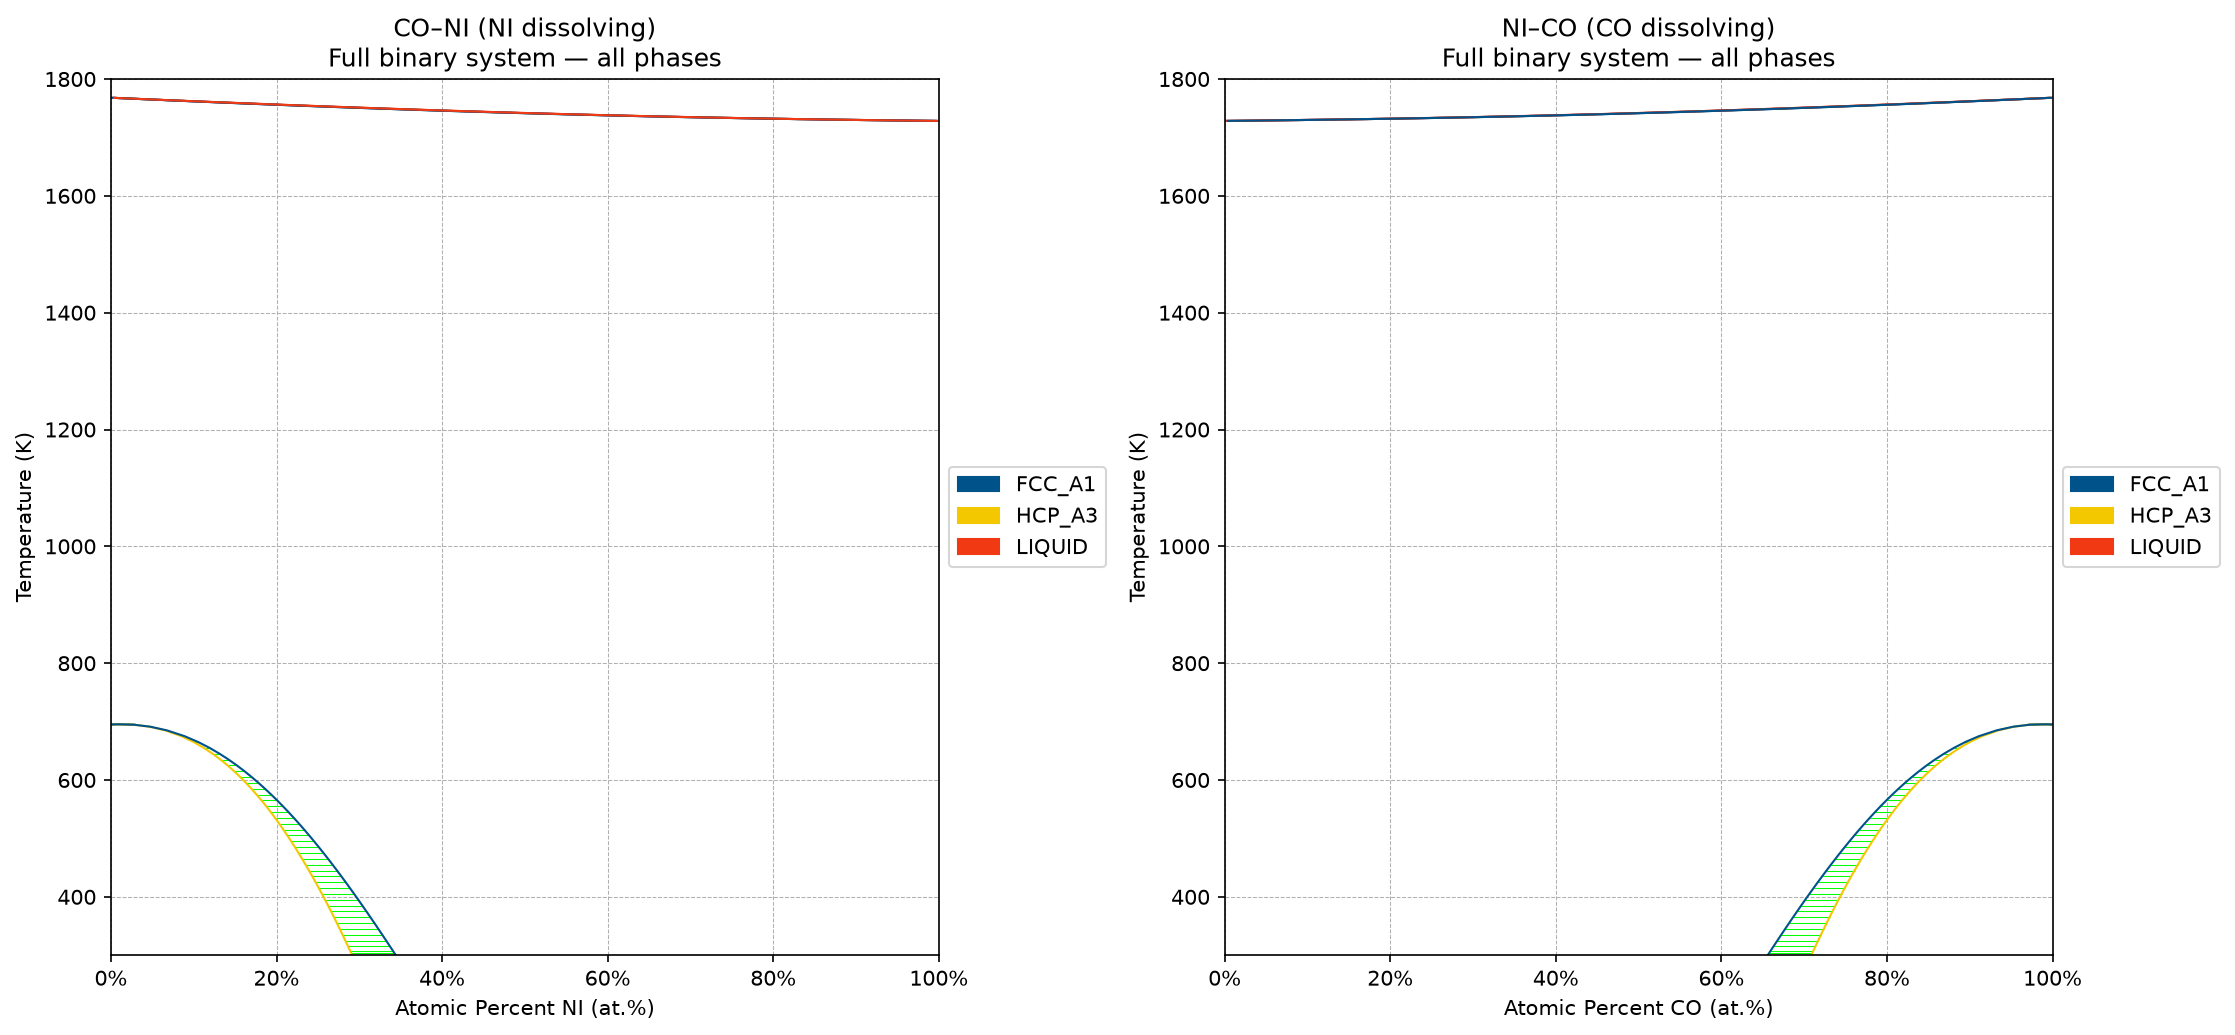

In [25]:
database = Database(selected_database)
calculation_components = validate_calculation_setup(
    database,
    binary_elements,
    all_phases,
)

print(f"Database: {selected_database.name}")
print(f"Components: {', '.join(calculation_components)}")
print(f"All phases: {', '.join(all_phases)}")

plot_diagram_pair(
    database,
    calculation_components,
    all_phases,
    full_atomic_fraction_range,
    temperature_range,
    "Full binary system — all phases",
)

## 2. Full binary system: stable FCC_A1 + LIQUID

This $0$–$100\,\mathrm{at.\%}$ view restricts equilibrium to the stable high-temperature solid `FCC_A1` and `LIQUID`. It reproduces the liquidus range in the all-phase diagram.

> **Why not BCC_A2?** A `BCC_A2` + `LIQUID` calculation artificially suppresses the stable `FCC_A1` phase. It therefore shows a metastable BCC/liquid transition near $1{,}300$–$1{,}550\,\mathrm{K}$ rather than the physical liquidus near $1{,}730$–$1{,}770\,\mathrm{K}$. `BCC_A2` is not the equilibrium solid next to the liquid in this Co–Ni database.

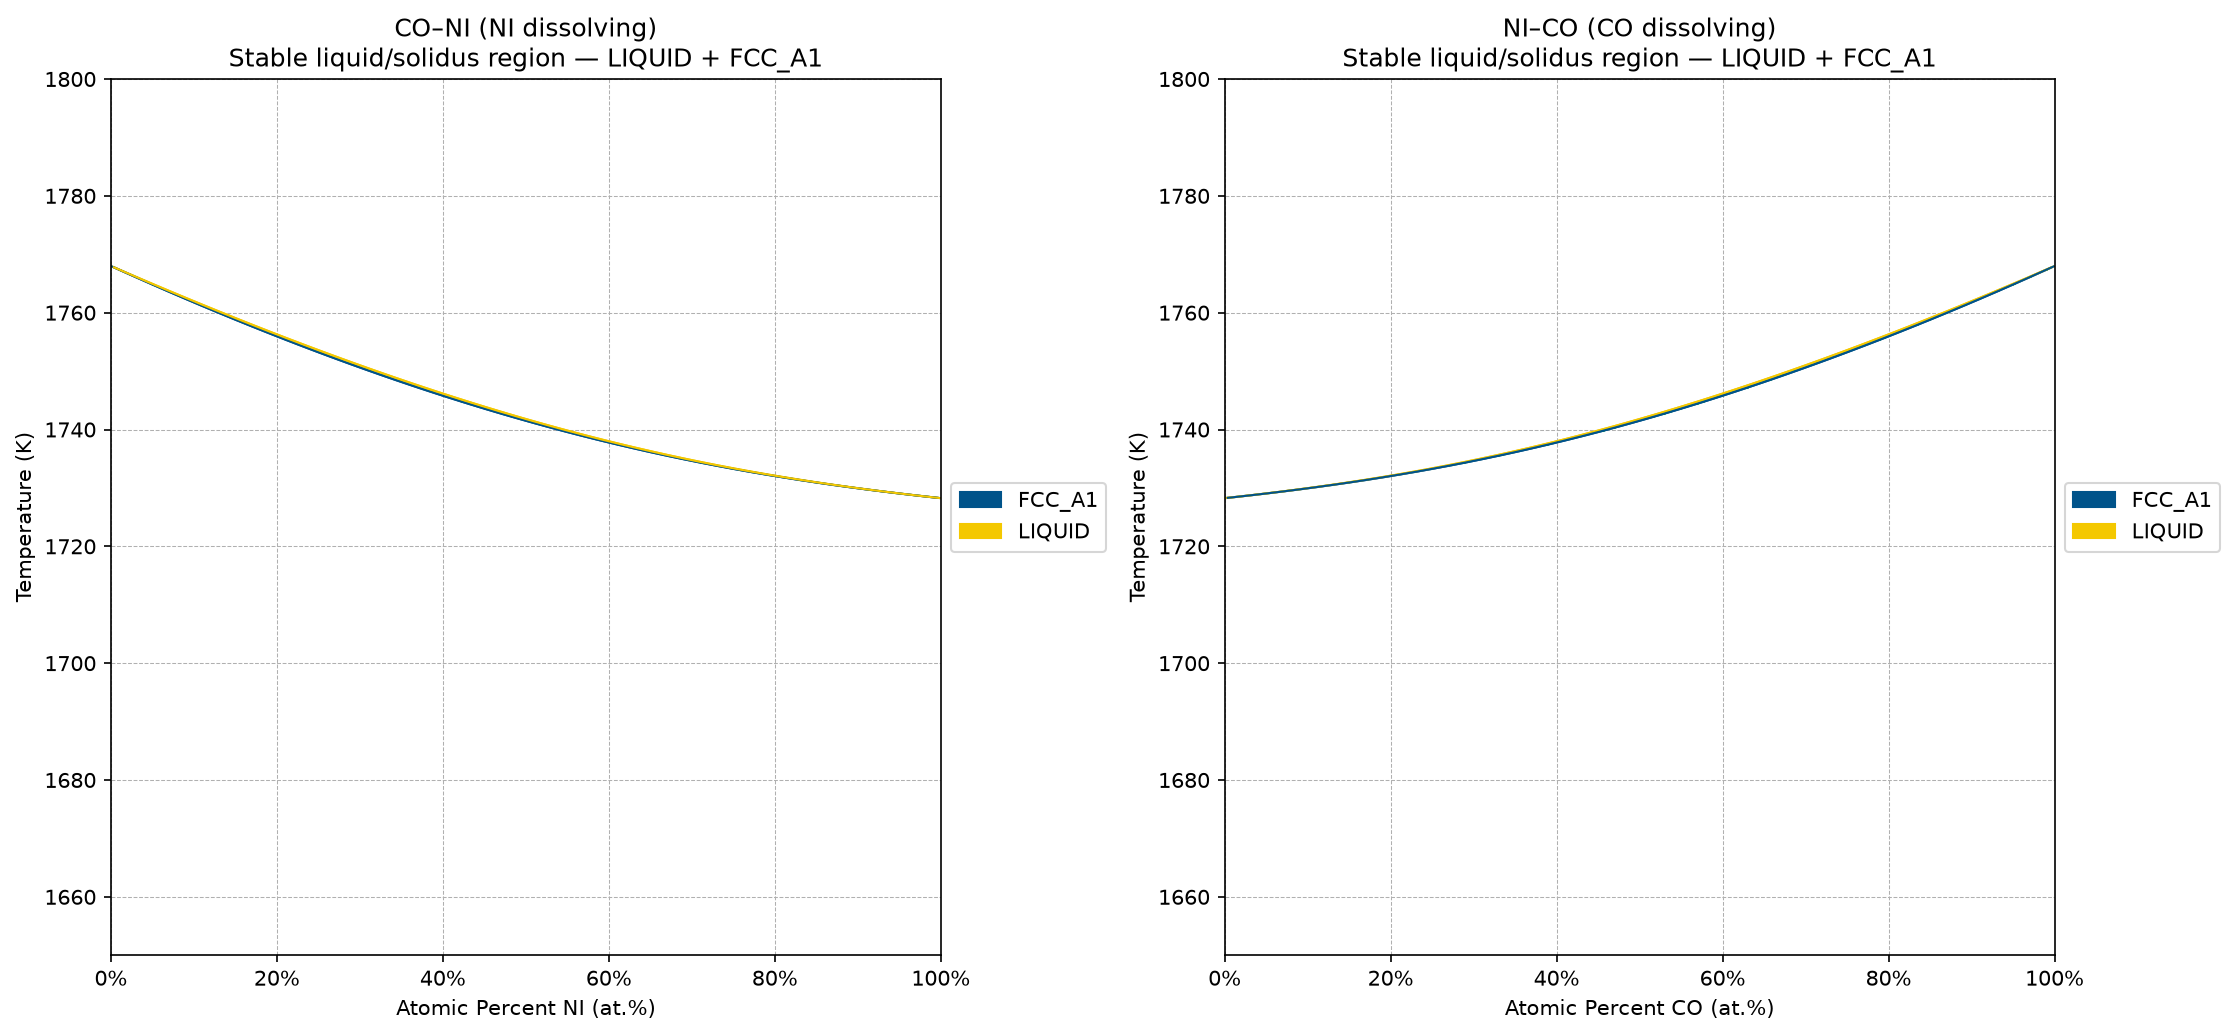

In [26]:
plot_diagram_pair(
    database,
    calculation_components,
    solid_liquid_phases,
    full_atomic_fraction_range,
    solid_liquid_temperature_range,
    "Stable liquid/solidus region — LIQUID + FCC_A1",
)

## 3. Focused system: 10–25 at.% FCC_A1 + LIQUID

This section generates **two separate figures** so each dissolving-element direction can use an independent temperature scale:

- Co–Ni with Ni dissolving; and
- Ni–Co with Co dissolving.

Circular markers identify each selected composition on the `FCC_A1`/solidus and `LIQUID`/liquidus boundaries. A table below each diagram lists the corresponding temperatures.

Use `focused_y_axis_ranges` in the settings cell to zoom each temperature axis without changing the thermodynamic calculation. Set either value to `None` for the full FCC_A1 + LIQUID calculation window.

### How the FCC_A1 + LIQUID boundary data points are calculated

The circular markers and tables are **not digitized or interpolated from the plotted curves**. For every selected composition, the notebook performs a new equilibrium calculation using the same TDB database and the restricted phase set `FCC_A1` + `LIQUID`. This is the correct high-temperature solid/liquid phase pair in the Co–Ni database.

For a dissolving-element concentration $c$ given in atomic percent, the equilibrium condition uses its atomic fraction:

$$
X_{\mathrm{dissolving}} = \frac{c}{100}, \qquad P = 101325\,\mathrm{Pa}, \qquad N = 1.
$$

At each trial temperature $T$, pycalphad minimizes the total Gibbs energy subject to these conditions and returns the equilibrium phase amounts $n_{\mathrm{FCC}}(T, X)$ and $n_{\mathrm{L}}(T, X)$. Their sum is approximately one for the selected two-phase model:

$$
n_{\mathrm{FCC}} + n_{\mathrm{L}} \approx 1.
$$

The table reports two boundary temperatures for each composition:

- **FCC_A1 boundary / solidus** $T_{\mathrm{s}}$: the first heating temperature where liquid is present,

$$
T_{\mathrm{s}} = \min\left\{T : n_{\mathrm{L}}(T, X) > \varepsilon\right\}.
$$

- **LIQUID boundary / liquidus** $T_{\mathrm{L}}$: the first heating temperature where the material is effectively all liquid,

$$
T_{\mathrm{L}} = \min\left\{T : n_{\mathrm{L}}(T, X) \geq 1-\varepsilon \ \text{and} \ n_{\mathrm{FCC}}(T, X) \leq \varepsilon\right\}.
$$

Here, $\varepsilon = 10^{-6}$ is `PHASE_AMOUNT_TOLERANCE`. Between $T_{\mathrm{s}}$ and $T_{\mathrm{L}}$, the calculation predicts an `FCC_A1` + `LIQUID` equilibrium region.

For efficiency, the code first scans the direction-specific `focused_boundary_temperature_ranges` in $5\,\mathrm{K}$ steps to bracket each transition. It then applies bisection until the bracket width is at most $0.1\,\mathrm{K}$ (`TEMPERATURE_TOLERANCE`). Therefore, the values in the table are direct equilibrium results with a transition-location uncertainty bounded by approximately $0.1\,\mathrm{K}$, rather than values read from the image.

> **Thermodynamic interpretation:** the earlier `BCC_A2` + `LIQUID` plots were metastable constrained calculations because they excluded the lower-Gibbs-energy `FCC_A1` phase. They are not Co–Ni equilibrium liquidus/solidus data. The calculations here use the stable high-temperature phase pair and match the all-phase diagram.

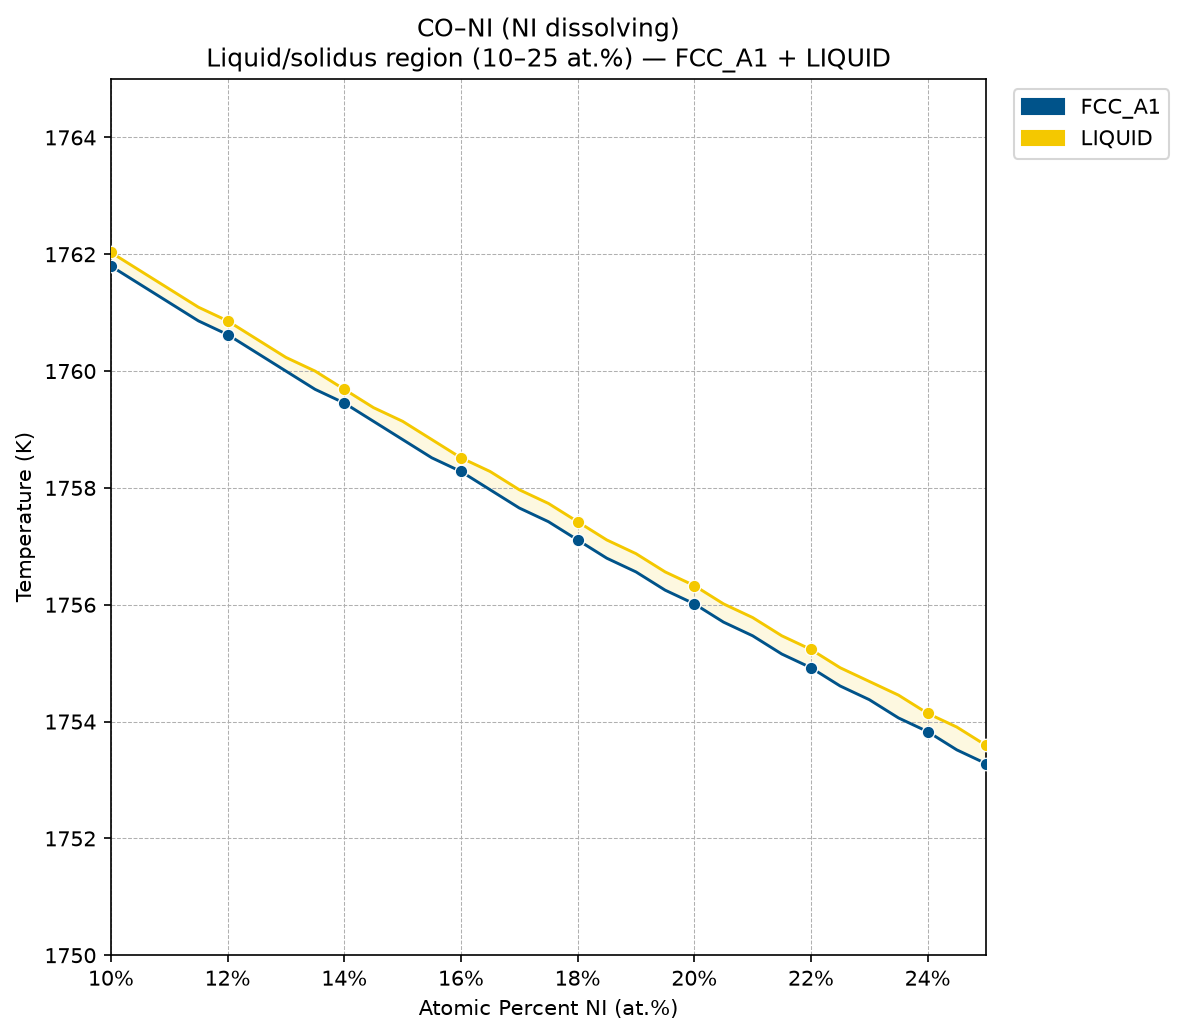

CO–NI (NI dissolving): selected FCC_A1 and LIQUID boundary temperatures


,NI (at.%),FCC_A1 boundary / solidus (K),LIQUID boundary / liquidus (K)
0,10.0,1761.8,1762.0
1,12.0,1760.6,1760.9
2,14.0,1759.5,1759.7
3,16.0,1758.3,1758.5
4,18.0,1757.1,1757.4
5,20.0,1756.0,1756.3
6,22.0,1754.9,1755.2
7,24.0,1753.8,1754.1
8,25.0,1753.3,1753.6


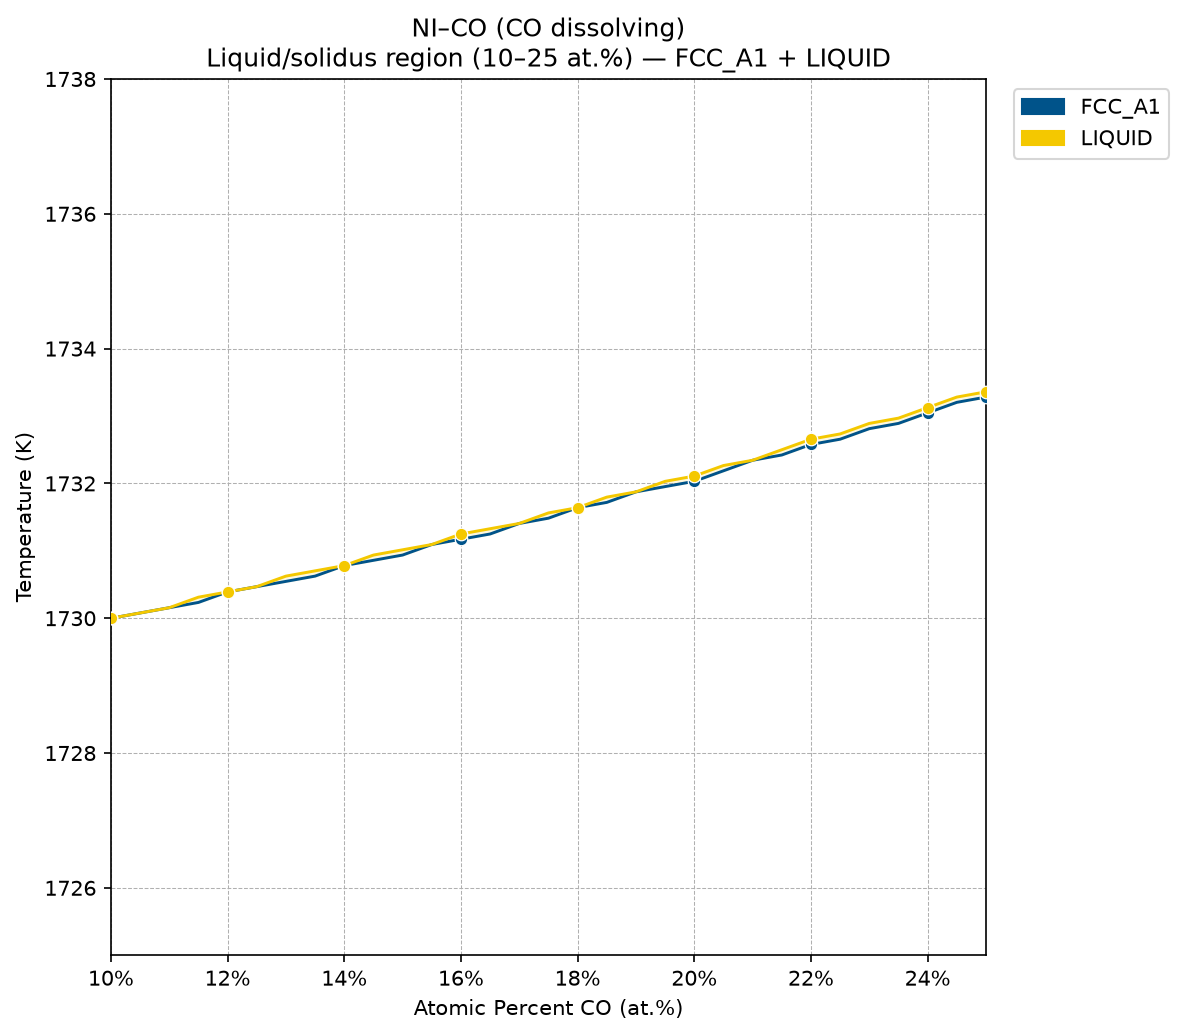

NI–CO (CO dissolving): selected FCC_A1 and LIQUID boundary temperatures


,CO (at.%),FCC_A1 boundary / solidus (K),LIQUID boundary / liquidus (K)
0,10.0,1730.0,1730.0
1,12.0,1730.4,1730.4
2,14.0,1730.8,1730.8
3,16.0,1731.2,1731.2
4,18.0,1731.6,1731.6
5,20.0,1732.0,1732.1
6,22.0,1732.6,1732.7
7,24.0,1733.0,1733.1
8,25.0,1733.3,1733.4


In [27]:
plot_focused_diagrams(
    database,
    calculation_components,
    focused_y_axis_ranges,
)